# Explainable Machine Learning for Gallstone Disease

## Libraries

In [41]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [42]:
gd_df = pd.read_csv("dataset-uci.csv")

## Exploratory Data Analysis (EDA)

In [43]:
gd_df.head(10).T

,0,1,2,3,4,5,6,7,8,9
Gallstone Status,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Age,50.00,47.00,61.00,41.00,42.00,96.00,37.00,41.00,38.00,38.00
Gender,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Comorbidity,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Coronary Artery Disease (CAD),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hypothyroidism,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hyperlipidemia,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Diabetes Mellitus (DM),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Height,185.00,176.00,171.00,168.00,178.00,155.00,185.00,176.00,186.00,171.00
Weight,92.80,94.50,91.10,67.70,89.60,49.00,67.10,114.00,93.70,68.60


In [44]:
gd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                     

In [45]:
gd_df.shape

(319, 39)

In [46]:
gd_df.isnull().sum()

Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (B

In [47]:
gd_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


In [48]:
gd_df.describe().T.sort_values("std", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Obesity (%),319.0,35.850125,109.799718,0.40,13.900,25.600000,41.750,1954.00
Triglyceride,319.0,144.502163,97.904493,1.39,83.000,119.000000,172.000,838.00
Total Cholesterol (TC),319.0,203.495298,45.758501,60.00,172.000,198.000000,233.000,360.00
Glucose,319.0,108.688715,44.848714,69.00,92.000,98.000000,109.000,575.00
Low Density Lipoprotein (LDL),319.0,126.652351,38.541175,11.00,100.500,122.000000,151.000,293.00
Alanin Aminotransferaz (ALT),319.0,26.855799,27.884413,3.00,14.250,19.000000,30.000,372.00
Alkaline Phosphatase (ALP),319.0,73.112539,24.181069,7.00,58.000,71.000000,86.000,197.00
High Density Lipoprotein (HDL),319.0,49.475549,17.718701,25.00,40.000,46.500000,56.000,273.00
Glomerular Filtration Rate (GFR),319.0,100.818903,16.971396,10.60,94.170,104.000000,110.745,132.00
Aspartat Aminotransferaz (AST),319.0,21.684953,16.697605,8.00,15.000,18.000000,23.000,195.00


In [49]:
gd_df.duplicated().sum()

0

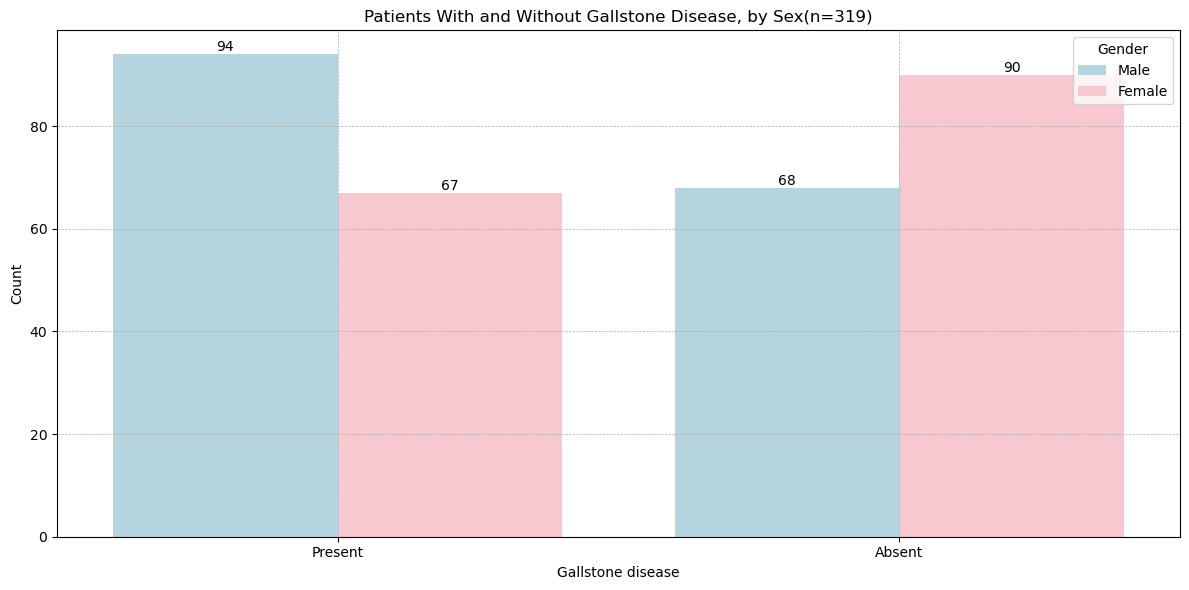

In [50]:
plt.figure(figsize=(12, 6))
plt.title("Patients With and Without Gallstone Disease, by Sex(n=319)")
ax = sns.countplot(x = "Gallstone Status", hue="Gender", data = gd_df, palette= ("lightblue", "pink"))
ax.set_xticklabels(["Present", "Absent"])

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Gallstone disease")
plt.ylabel("Count")
plt.tight_layout()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend(title="Gender", loc="upper right", labels=["Male", "Female"])
plt.show()

After inspecting the dataset statistics (describe()) we noticed obesity had a large standard deviation. This should be taken a closer look at later.

In [51]:
gd_df[["Obesity (%)", "Height", "Weight"]].sort_values("Obesity (%)", ascending=False).head() # anomaly ? 

,Obesity (%),Height,Weight
239,1954.00,150,65.9
23,125.60,170,143.5
209,106.30,150,102.1
280,96.63,150,108.4
246,95.64,162,125.8


In [52]:
gd_df[["Triglyceride", "Height", "Weight"]].sort_values("Triglyceride", ascending=False).head() # anomaly ? 

,Triglyceride,Height,Weight
242,838.0,173,87.8
20,692.0,178,110.7
8,679.0,186,93.7
7,464.0,176,114.0
50,455.0,167,82.2


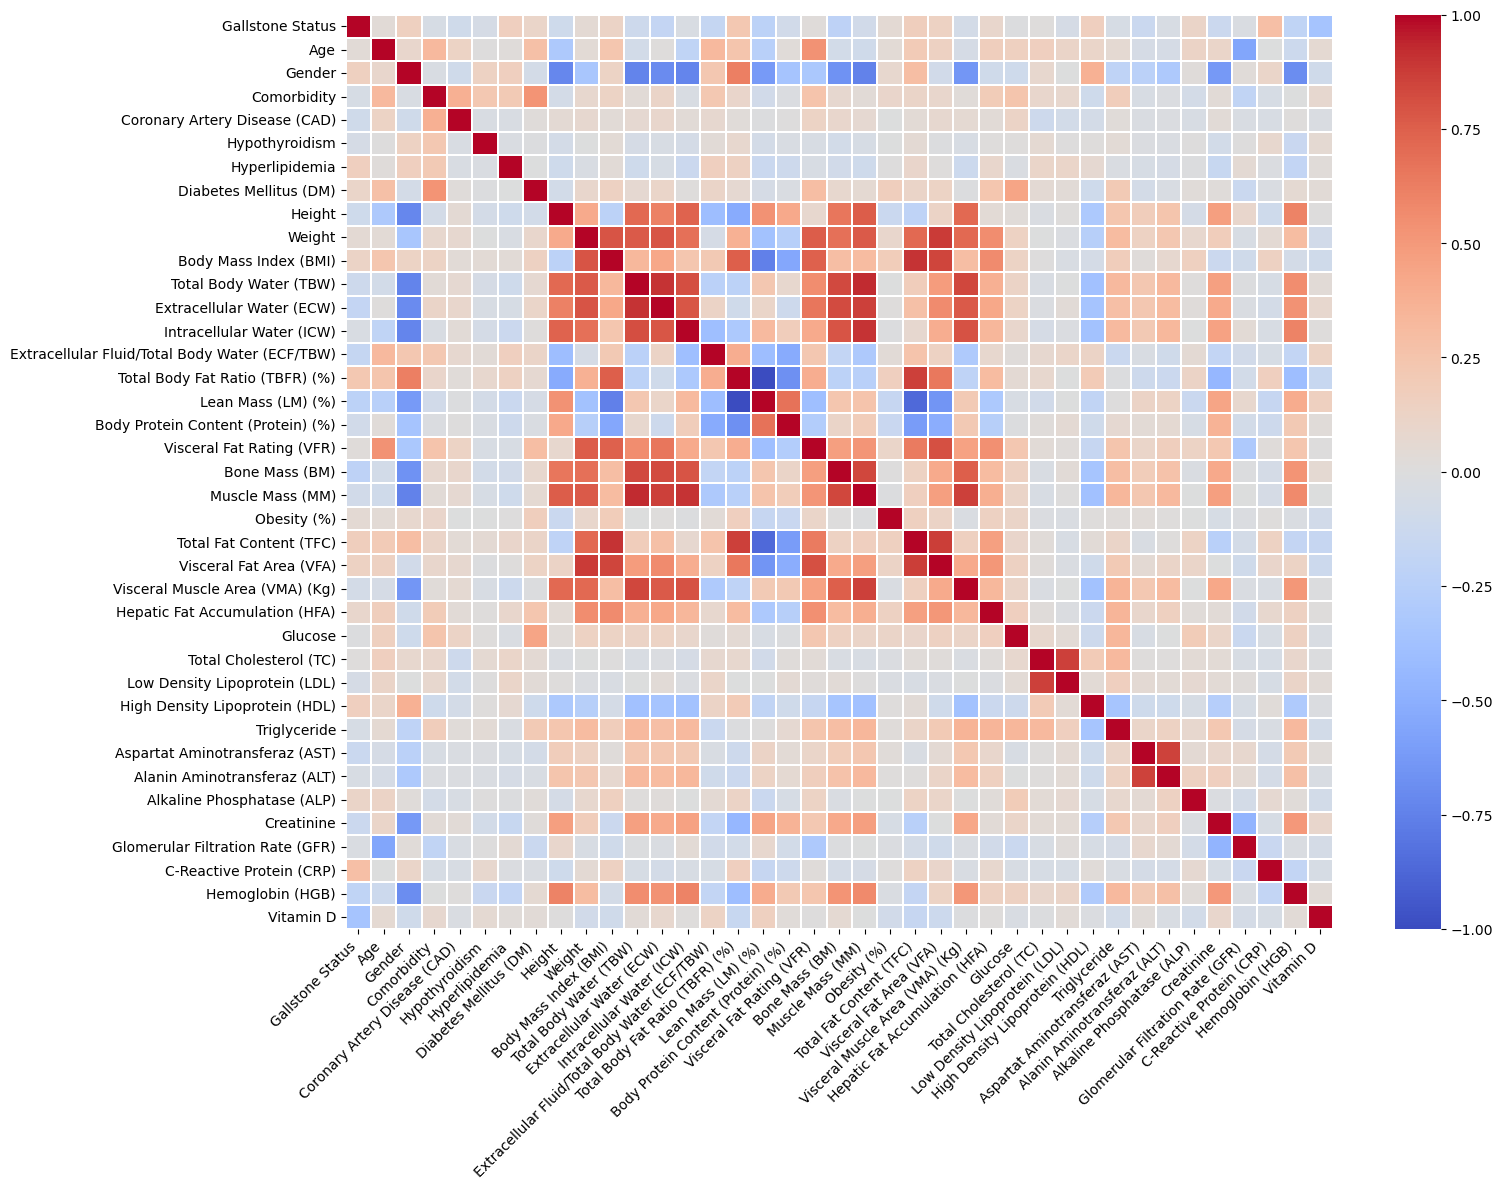

In [53]:
plt.figure(figsize=(16, 12))
sns.heatmap(gd_df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [54]:
gd_df[["Gallstone Status", "C-Reactive Protein (CRP)"]].sort_values("C-Reactive Protein (CRP)", ascending=False).T

,214,272,231,153,270,268,257,280,277,208,...,124,125,126,127,128,129,130,131,132,318
Gallstone Status,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
C-Reactive Protein (CRP),43.4,36.7,36.1,31.0,24.5,21.4,18.8,16.5,14.0,13.9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [55]:
no_gallstone = gd_df[gd_df["Gallstone Status"] == 1]
no_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,158.0,1.000000,0.000000,1.00,1.000000,1.000000,1.000000,1.00
Age,158.0,48.512658,11.200397,20.00,39.250000,50.000000,56.000000,76.00
Gender,158.0,0.569620,0.496704,0.00,0.000000,1.000000,1.000000,1.00
Comorbidity,158.0,0.310127,0.464016,0.00,0.000000,0.000000,1.000000,1.00
Coronary Artery Disease (CAD),158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hypothyroidism,158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hyperlipidemia,158.0,0.050633,0.219944,0.00,0.000000,0.000000,0.000000,1.00
Diabetes Mellitus (DM),158.0,0.170886,0.377606,0.00,0.000000,0.000000,0.000000,1.00
Height,158.0,166.063291,10.247065,146.00,158.000000,165.000000,174.000000,191.00
Weight,158.0,81.335443,15.444613,42.90,70.225000,79.850000,92.150000,125.80


In [56]:
has_gallstone = gd_df[gd_df["Gallstone Status"] == 0]
has_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Age,161.0,47.633540,12.969527,20.00,38.000,49.00,56.00,96.00
Gender,161.0,0.416149,0.494457,0.00,0.000,0.00,1.00,1.00
Comorbidity,161.0,0.360248,0.565164,0.00,0.000,0.00,1.00,3.00
Coronary Artery Disease (CAD),161.0,0.055901,0.230447,0.00,0.000,0.00,0.00,1.00
Hypothyroidism,161.0,0.037267,0.190007,0.00,0.000,0.00,0.00,1.00
Hyperlipidemia,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Diabetes Mellitus (DM),161.0,0.099379,0.300104,0.00,0.000,0.00,0.00,1.00
Height,161.0,168.229814,9.771929,145.00,162.000,170.00,175.00,188.00
Weight,161.0,79.808696,15.976226,47.30,69.200,78.00,90.50,143.50


In [57]:
gd_df.corrwith(gd_df["Gallstone Status"])

Gallstone Status                                  1.000000
Age                                               0.036339
Gender                                            0.153483
Comorbidity                                      -0.048516
Coronary Artery Disease (CAD)                    -0.096998
Hypothyroidism                                   -0.055196
Hyperlipidemia                                    0.161901
Diabetes Mellitus (DM)                            0.104689
Height                                           -0.107919
Weight                                            0.048669
Body Mass Index (BMI)                             0.121507
Total Body Water (TBW)                           -0.111233
Extracellular Water (ECW)                        -0.178436
Intracellular Water (ICW)                        -0.035274
Extracellular Fluid/Total Body Water (ECF/TBW)   -0.169826
Total Body Fat Ratio (TBFR) (%)                   0.225470
Lean Mass (LM) (%)                               -0.2257

## Separating features and label

In [58]:
x = gd_df.drop(["Gallstone Status"], axis = 1)

# In dataset 0 means a person has Gallstone Disease, while 1 means a person does not have Gallstone Disease
# We prefer it the other way around and therefore change this to 1 = sick, 0 = healthy
y = 1 - gd_df["Gallstone Status"]

## Train/Test Split

In [90]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.1, random_state=1, stratify=y_train)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)

(229, 38)
(229,)
(64, 38) (64,)
(26, 38) (26,)


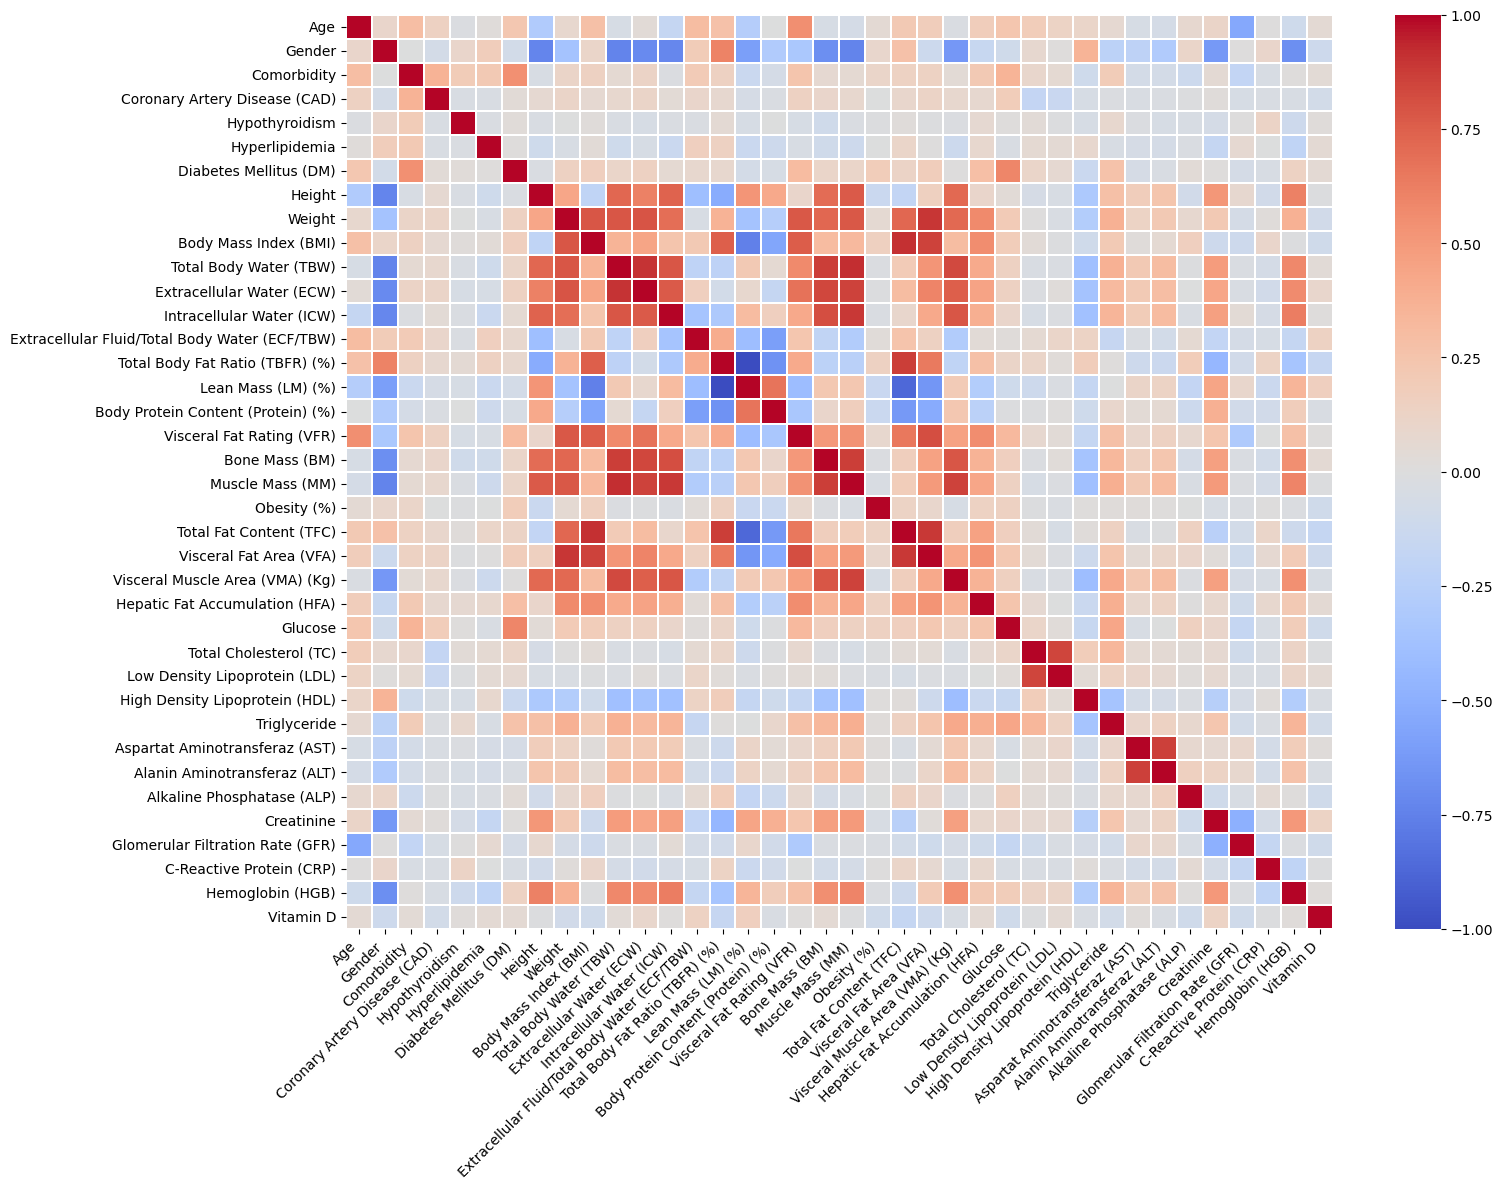

In [91]:
plt.figure(figsize=(16, 12))
sns.heatmap(x_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [92]:
# correlation values between features
corr = x_train.corr().abs()

corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = corr[(corr > 0.8) & (corr != 1)].stack()

high_corr.sort_values(ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)                 0.998335
Total Body Water (TBW)           Muscle Mass (MM)                   0.921544
Body Mass Index (BMI)            Total Fat Content (TFC)            0.909599
Total Body Water (TBW)           Extracellular Water (ECW)          0.904026
Weight                           Visceral Fat Area (VFA)            0.891778
Total Fat Content (TFC)          Visceral Fat Area (VFA)            0.887591
Intracellular Water (ICW)        Muscle Mass (MM)                   0.884399
Total Body Fat Ratio (TBFR) (%)  Total Fat Content (TFC)            0.872343
Lean Mass (LM) (%)               Total Fat Content (TFC)            0.871298
Bone Mass (BM)                   Muscle Mass (MM)                   0.868665
Total Body Water (TBW)           Bone Mass (BM)                     0.868041
Aspartat Aminotransferaz (AST)   Alanin Aminotransferaz (ALT)       0.866716
Body Mass Index (BMI)            Visceral Fat Area (VFA)            0.854825

In [93]:
x_train[["Total Body Fat Ratio (TBFR) (%)", "Lean Mass (LM) (%)"]].corr()

,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%)
Total Body Fat Ratio (TBFR) (%),1.000000,-0.998335
Lean Mass (LM) (%),-0.998335,1.000000


In [94]:
mutual_info = mutual_info_classif(x_train, y_train, random_state=1)
mutual_info = pd.Series(mutual_info, index = x_train.columns).sort_values(ascending=False)
mutual_info

C-Reactive Protein (CRP)                          0.232719
Total Cholesterol (TC)                            0.128782
Intracellular Water (ICW)                         0.114022
Extracellular Water (ECW)                         0.104408
High Density Lipoprotein (HDL)                    0.071757
Body Protein Content (Protein) (%)                0.067932
Alkaline Phosphatase (ALP)                        0.050315
Vitamin D                                         0.046805
Muscle Mass (MM)                                  0.043202
Diabetes Mellitus (DM)                            0.042330
Glucose                                           0.040848
Alanin Aminotransferaz (ALT)                      0.038331
Extracellular Fluid/Total Body Water (ECF/TBW)    0.037497
Total Body Water (TBW)                            0.024265
Triglyceride                                      0.019181
Coronary Artery Disease (CAD)                     0.017996
Bone Mass (BM)                                    0.0174

In [95]:
drop_features = ["Total Body Water (TBW)", "Lean Mass (LM) (%)", "Obesity (%)"] # justification in feature_selection.md

x_train_selected = x_train.drop(columns=drop_features)
x_test_selected = x_test.drop(columns=drop_features)

# now only 35 features
print(x_train_selected.shape)
print(x_test_selected.shape)

(229, 35)
(64, 35)


Til neste gang: må velge meassurement typer (accuracy, precision, recall, f1, roc-auc). Deretter kjøre Cross-validation. 

Using sklearns pipeline

In [96]:
models = {
"Logistic Regression" : Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
]),

"Random Forest" : Pipeline([
    ("model", RandomForestClassifier())
]),

"Gradient Boost" : Pipeline([
    ("model", GradientBoostingClassifier())
]), 

"SVM" : Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())])
}

In [97]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

In [98]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

In [99]:
results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        x_train_selected,
        y_train,
        cv=cross_validation,
        scoring=scoring
    )

    results[name] = scores

In [100]:
results_all = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=cross_validation,
        scoring=scoring
    )

    results_all[name] = scores

### Results of 5-fold with 35 features

In [74]:
comparison = pd.DataFrame()

for name, scores in results.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.784 ± 0.071,0.766 ± 0.065,0.829 ± 0.087,0.795 ± 0.068,0.848 ± 0.071
Random Forest,0.749 ± 0.049,0.733 ± 0.048,0.790 ± 0.062,0.760 ± 0.053,0.841 ± 0.045
Gradient Boost,0.733 ± 0.049,0.721 ± 0.041,0.767 ± 0.067,0.743 ± 0.052,0.802 ± 0.058
SVM,0.725 ± 0.055,0.694 ± 0.049,0.822 ± 0.089,0.751 ± 0.054,0.802 ± 0.038


### Results of 5-fold with 38 features

In [76]:
comparison = pd.DataFrame()

for name, scores in results_all.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.780 ± 0.069,0.761 ± 0.065,0.829 ± 0.087,0.792 ± 0.066,0.843 ± 0.061
Random Forest,0.780 ± 0.050,0.771 ± 0.055,0.806 ± 0.058,0.787 ± 0.051,0.834 ± 0.065
Gradient Boost,0.745 ± 0.041,0.739 ± 0.029,0.767 ± 0.090,0.750 ± 0.050,0.805 ± 0.055
SVM,0.729 ± 0.040,0.698 ± 0.033,0.822 ± 0.067,0.754 ± 0.039,0.804 ± 0.036
